# 20 - Answer or hand off: a certified error rate for the answers Quill gives

> "Quill should answer on its own only when it is likely to be right, and send every other question to a human tutor. Can we promise that at most one in ten of the answers it gives on its own is wrong?" - Quill product lead

The product lead has stopped asking for shortlists. A student who sees one answer, alone and without a hedge, takes it as the answer, so Quill should show one only when it is likely to be right and hand every other question to a tutor. That is one binary action per question, answer alone or hand off, and the dial is a threshold on how sure the model is. The promise is about the questions Quill keeps: among them, the error rate, which the literature calls the **selective risk**, must be at most a level epsilon. And since the threshold is learned from a finite calibration set, the promise needs a second number: how sure we are that this calibration set did not mislead us. So the sharper statistical question is: from labelled calibration questions, can we choose a threshold so that, with probability at least 1 - delta over the draw of the calibration set, the error rate among the questions Quill answers alone is at most epsilon; how many questions does Quill still answer; and what should it do when no threshold earns the promise?

Two shortcuts look like answers, and we commit both. The first reads the 90% shortlist of notebook 17 as the promise: answer alone when the shortlist has one option. The second reads the calibration curve and ships the loosest threshold whose calibration error is at most epsilon. The tool that works is the one notebook 19 used for retrieval depth, Learn then Test, here with a binomial test on the answered calibration questions only: the construction of Geifman and El-Yaniv (2017) for selective classification, run with the fixed-sequence testing of Angelopoulos, Bates, Candes, Jordan and Lei (2021).

**What you will learn**

- Why a 90% coverage promise is not a promise about the answers Quill gives alone: the singletons of a 90% shortlist only satisfy "error among answered at most alpha divided by the share answered".
- Why shipping the loosest threshold whose calibration error is at most epsilon breaks the promise far more often than delta, measured over 2,000 redrawn calibration sets.
- How to certify a threshold: a binomial p-value on the answered calibration questions, fixed-sequence testing from the strictest threshold, the loosest certified threshold shipped, and the exact assumption this needs (an i.i.d. sample of the questions Quill will serve); and why a test reading above epsilon is not, by itself, a broken promise.
- Why "hand every question to a tutor" is a legitimate result, and how many answered calibration questions a certificate needs before it can exist at all.

**Where we are in the series.** Part III gave Quill shortlists (notebook 17), filtered explainers (notebook 18) and a retrieval depth (notebook 19). This notebook closes it with the simplest product decision of all: one answer or none. It leans on notebook 03 (the coverage lottery, and the difference between a promise averaged over calibration draws and one that holds for this draw), notebook 04 and field guide §7 (set size as a triage signal), notebook 09 (exchangeable is not independent), notebook 16 (the token probability ranks right above wrong answers best of the three readings), notebook 17 (the LAC shortlist and the cached data) and notebook 19 (Learn then Test, binomial p-values, fixed-sequence testing). Field guide §24-§28 summarize Part III, and §29 is this notebook's lesson.

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_SEED = 20260707
ALPHA = 0.10   # the 90% shortlist of notebook 17, used in section 2

# Series palette: blue = data, green = covered/healthy, amber = calibration/warning,
# red = missed/fault/naive, gray = reference, purple = alternative method.
BLUE, GREEN, AMBER, RED, GRAY, PURPLE = (
    "#2563EB", "#059669", "#F59E0B", "#DC2626", "#6B7280", "#7C3AED",
)

## 1. One answer, or a tutor

The action is binary. For every question, Quill either shows its top option alone or hands the question to a tutor, and it decides with a threshold on one score: the top option's token probability, $\hat p_{\max}(x)$, from the base procedure of notebook 16 (temperature 0, first-token log-probabilities renormalized over A to D). Quill answers alone when $\hat p_{\max}(x) \ge t$. Two numbers describe a threshold $t$. The **answer rate** is the share of questions Quill answers alone. The selective risk is the share of those answers that are wrong:

$$R(t) = \Pr\big(\text{top option wrong} \mid \hat p_{\max}(X) \ge t\big) = \frac{\Pr\big(\text{top option wrong and } \hat p_{\max}(X) \ge t\big)}{\Pr\big(\hat p_{\max}(X) \ge t\big)},$$

where $X$ is a question drawn from the traffic the promise is about. One caution on vocabulary: papers on selective classification call the answer rate "coverage". In this course coverage means that a set contains the answer key, so we say answer rate throughout.

The promise has the $(\epsilon, \delta)$ form that Learn then Test calls a risk-controlling prediction (its Definition 1) and Geifman and El-Yaniv state as their goal (their equation 2): a threshold $\hat t$ chosen from the calibration set such that

$$\Pr\big(R(\hat t) \le \epsilon\big) \ge 1 - \delta,$$

where the probability is over the draw of the calibration set. Both numbers are fixed before calibrating. **Epsilon = 0.10** is the product lead's requirement, not a knob: Quill unfiltered is wrong on about one question in five (notebook 16), so "at most one in ten of the answers it gives alone" halves what a student meets. It also matches the 90% that every shortlist in the course has promised, which section 2 puts to work. Notebook 19 used a pilot set to learn which epsilon its data could support; here epsilon is given, and the calibration set answers whether it can be certified. **Delta = 0.10**, as in notebook 19: one calibration draw in ten may be a bad ticket. The head of learning would prefer one wrong answer in twenty; section 5 shows what this calibration set can say about that.

The third thing fixed in advance is the list of candidate thresholds and the order in which they will be tested. Quill's probabilities are extremely peaked (notebook 17), so a grid evenly spaced in $t$ would put almost every candidate where no question lives. We space the grid by $1 - t$, the probability left for the other three options, in half-decades from $10^{-12}$ to $10^{-0.5}$, and add the two ends: $t = 1$ (answer only when the API reported no rival letter at all among its 20 most likely first tokens, notebook 17's resolution floor) and $t = 0.25$ (answer everything: the top option of four always has at least 0.25). That is 26 thresholds, written from the strictest to the loosest. Like epsilon, the grid must not depend on the calibration set. The data and the split are notebook 17's: the base run of `mmlu_llm_outputs.csv`, and the same seeded half-and-half split into 1,256 calibration and 1,257 test questions.

A note on this notebook's own choices, because the method depends on them. These questions and this split were already used in notebooks 16 and 17, which read their labels, and the grid was shaped from these very scores (the next printout shows why). So the single-split certificate in section 4 is a worked example of the arithmetic, not a certificate anyone could sign. The evidence that the procedure keeps its promise is the repeated-draw check of sections 3 and 4: there epsilon, delta and the grid are fixed relative to the 2,513-question bank before every one of 2,000 fresh calibration draws, and an epsilon sweep shows that the conclusion does not hinge on 0.10. In production, fix all four, epsilon, delta, the grid and its order, on a pilot sample or from earlier runs before the calibration labels are collected.

In [2]:
EPSILON = 0.10   # the product lead's promise: at most 10% of the answers given alone are wrong
DELTA = 0.10     # ... with probability at least 0.90 over the draw of the calibration set

questions = pd.read_csv("llm_data/mmlu_questions.csv")
outputs = pd.read_csv("llm_data/mmlu_llm_outputs.csv")
mmlu = questions.merge(outputs, on="qid", validate="one_to_one")
assert len(mmlu) == len(questions) == len(outputs), "every question needs exactly one row of model output"

LETTERS = ["A", "B", "C", "D"]
# token probabilities of the four letters (base procedure: temperature 0, renormalized over A-D)
probs = mmlu[[f"base_p{L}" for L in LETTERS]].to_numpy()
truth = mmlu["answer"].map({L: k for k, L in enumerate(LETTERS)}).to_numpy()
assert np.allclose(probs.sum(axis=1), 1.0, atol=1e-5), "base_p* must sum to one: they are renormalized over A-D"
n_q = len(truth)

# The score and the action: Quill shows its top option alone when p_top >= t. Three questions have
# a tied top probability (at most 0.5), so only the answer-everything threshold ever shows them;
# argmax then shows the first of the tied letters.
p_top = probs.max(axis=1)
wrong = probs.argmax(axis=1) != truth

# The seeded split of notebooks 16 and 17: half calibration, half test.
rng = np.random.default_rng(RANDOM_SEED)
perm = rng.permutation(n_q)
cal, test = np.sort(perm[: n_q // 2]), np.sort(perm[n_q // 2 :])
assert len(np.intersect1d(cal, test)) == 0, "a question in both halves would leak its answer into the threshold"

# The grid, fixed before the labels are used here, strictest first, spaced by 1 - t.
RIVAL_EXPONENTS = np.arange(12.0, 0.49, -0.5)                 # 1 - t = 10^-12, 10^-11.5, ..., 10^-0.5
GRID = np.concatenate([[1.0], 1.0 - 10.0 ** -RIVAL_EXPONENTS, [0.25]])
GRID_LABEL = ["t = 1"] + [f"1 - 10^-{k:g}" for k in RIVAL_EXPONENTS] + ["t = 0.25 (all)"]
assert np.all(np.diff(GRID) < 0), "the grid must run from the strictest threshold to the loosest"
# first_passed[i] is the strictest grid threshold question i passes. Thresholds only loosen along the
# grid, so question i is answered alone at GRID[j] exactly when j >= first_passed[i].
first_passed = (p_top[:, None] < GRID[None, :]).sum(axis=1)
assert np.all(p_top >= GRID[first_passed]), "every question must pass its own first threshold"


def counts_by_threshold(idx):
    """Answered (m) and answered-and-wrong (e) counts at every grid threshold, for the questions `idx`."""
    m = np.cumsum(np.bincount(first_passed[idx], minlength=len(GRID)))
    e = np.cumsum(np.bincount(first_passed[idx], weights=wrong[idx], minlength=len(GRID))).astype(int)
    return m, e


print(f"{n_q:,} questions: {len(cal):,} calibration, {len(test):,} test (the split of notebooks 16 and 17)")
print(f"the top option is wrong on {wrong[cal].mean():.1%} of calibration and {wrong[test].mean():.1%} of test questions")
print("share of calibration questions whose top option reaches t (scores only, no labels):")
for label, t in [("0.99", 0.99), ("0.999", 0.999), ("1 - 10^-6", 1 - 1e-6), ("1 - 10^-9", 1 - 1e-9), ("1 exactly", 1.0)]:
    print(f"   t = {label:10s} {np.mean(p_top[cal] >= t):6.1%}")
print(f"median probability left for the other three options: {np.median(1 - p_top[cal]):.1e}")
print(f"grid: {len(GRID)} thresholds, strictest first: {', '.join(GRID_LABEL[:3])}, ..., {', '.join(GRID_LABEL[-2:])}")

2,513 questions: 1,256 calibration, 1,257 test (the split of notebooks 16 and 17)
the top option is wrong on 19.7% of calibration and 20.8% of test questions
share of calibration questions whose top option reaches t (scores only, no labels):
   t = 0.99        82.6%
   t = 0.999       76.8%
   t = 1 - 10^-6   66.6%
   t = 1 - 10^-9   41.7%
   t = 1 exactly    7.3%
median probability left for the other three options: 3.7e-09
grid: 26 thresholds, strictest first: t = 1, 1 - 10^-12, 1 - 10^-11.5, ..., 1 - 10^-0.5, t = 0.25 (all)


The top option is wrong on 19.7% of the calibration questions and 20.8% of the test questions, Quill's one-in-five. The score distribution explains the strange-looking grid. On 82.6% of calibration questions the top option gets at least 0.99, on 41.7% it is within a billionth of 1, and on 7.3% it is exactly 1 because no rival letter made the API's top 20 tokens; the median probability left for the other three options is $3.7 \times 10^{-9}$. A grid spaced evenly in $t$, say 0.90, 0.91, ..., 0.99, would spend every candidate on the 17% of questions below 0.99 and say nothing about the rest. The thresholds that matter are written in powers of ten, and if they look absurd, recall notebook 17: this model's mistakes are usually confident ones, which is what put its shortlist bar at 0.001.

Now the calibration half's labels. For each grid threshold we count the calibration questions Quill would answer alone, and how many of those it gets wrong.

t = 1           answered    92 ( 7.3%), wrong   3: error among answered 0.0326
1 - 10^-11.5    answered   190 (15.1%), wrong   9: error among answered 0.0474
1 - 10^-10      answered   361 (28.7%), wrong  13: error among answered 0.0360
1 - 10^-9.5     answered   428 (34.1%), wrong  22: error among answered 0.0514
1 - 10^-9       answered   524 (41.7%), wrong  28: error among answered 0.0534
1 - 10^-3       answered   964 (76.8%), wrong  90: error among answered 0.0934
1 - 10^-2.5     answered   995 (79.2%), wrong 102: error among answered 0.1025
t = 0.25 (all)  answered  1256 (100.0%), wrong 248: error among answered 0.1975


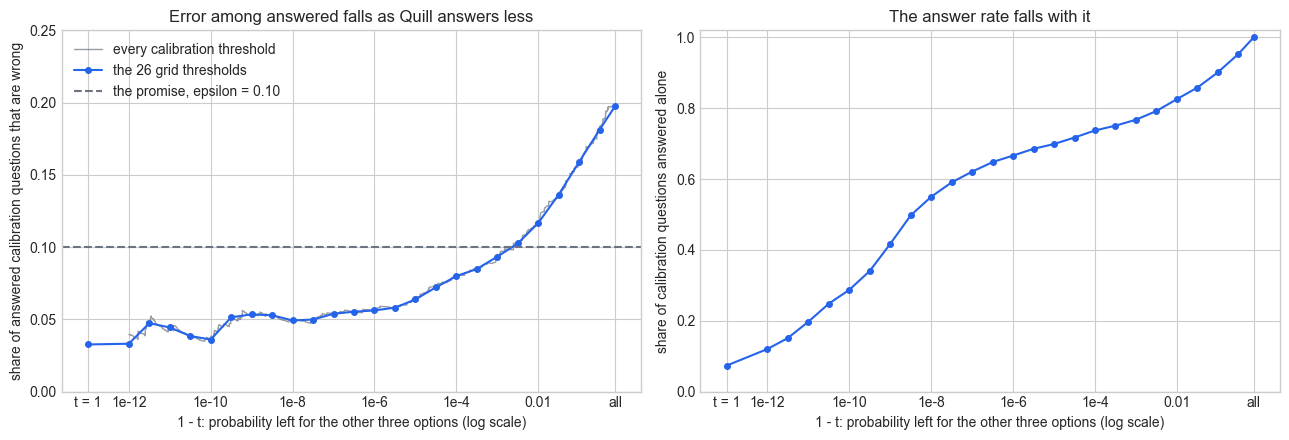

In [3]:
m_cal, e_cal = counts_by_threshold(cal)
risk_cal = e_cal / m_cal
x_grid = np.where(GRID == 1.0, -13.0, np.log10(np.maximum(1.0 - GRID, 1e-13)))   # t = 1 gets a tick of its own

# The same curve at every calibration threshold, not just the grid: the k most confident questions,
# drawn where the log axis has room for it (from 1 - t = 10^-12 on).
order = np.argsort(-p_top[cal], kind="stable")
drawn = 1.0 - p_top[cal][order] >= 1e-12
x_every = np.log10(1.0 - p_top[cal][order][drawn])
risk_every = (np.cumsum(wrong[cal][order]) / np.arange(1, len(cal) + 1))[drawn]

for label in ["t = 1", "1 - 10^-11.5", "1 - 10^-10", "1 - 10^-9.5", "1 - 10^-9", "1 - 10^-3", "1 - 10^-2.5", "t = 0.25 (all)"]:
    j = GRID_LABEL.index(label)
    print(f"{label:15s} answered {m_cal[j]:5d} ({m_cal[j] / len(cal):5.1%}), wrong {e_cal[j]:3d}: "
          f"error among answered {risk_cal[j]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ticks = [-13, -12, -10, -8, -6, -4, -2, np.log10(0.75)]
tick_labels = ["t = 1", "1e-12", "1e-10", "1e-8", "1e-6", "1e-4", "0.01", "all"]
axes[0].plot(x_every, risk_every, color=GRAY, linewidth=1, alpha=0.7, label="every calibration threshold")
axes[0].plot(x_grid, risk_cal, "o-", color=BLUE, markersize=4, label="the 26 grid thresholds")
axes[0].axhline(EPSILON, color=GRAY, linestyle="--", label=f"the promise, epsilon = {EPSILON:.2f}")
axes[0].set_ylim(0, 0.25)
axes[0].set_ylabel("share of answered calibration questions that are wrong")
axes[0].set_title("Error among answered falls as Quill answers less")
axes[0].legend(loc="upper left")
axes[1].plot(x_grid, m_cal / len(cal), "o-", color=BLUE, markersize=4)
axes[1].set_ylim(0, 1.02)
axes[1].set_ylabel("share of calibration questions answered alone")
axes[1].set_title("The answer rate falls with it")
for ax in axes:
    ax.set_xticks(ticks)
    ax.set_xticklabels(tick_labels)
    ax.set_xlabel("1 - t: probability left for the other three options (log scale)")
plt.tight_layout()
plt.show()

Read the left panel from right to left. Answering every question, Quill is wrong on 19.7% of the calibration half; as the threshold tightens the error among answered falls, to 9.3% at $t = 1 - 10^{-3}$ (76.8% answered), 5.3% at $1 - 10^{-9}$ (41.7%) and 3.3% at $t = 1$, where only 92 calibration questions are left. The right panel is the price: every point of error removed is paid for in questions handed to a tutor.

Two features of this curve shape everything that follows. First, it is noisy at the strict end, because few questions are answered there: the gray line, the same curve at every calibration threshold, wiggles wherever the count is small. Second, it is not monotone. Loosening from $1 - 10^{-11.5}$ to $1 - 10^{-10}$ lowers the error among answered from 4.7% to 3.6%, and the next half-decade lifts it to 5.1%. Some of that is noise, but nothing promises monotonicity either: $R(t)$ is a ratio, and loosening the threshold adds a band of questions, so when the band happens to be easier than the questions already answered, the ratio falls. A score that ranked every right answer above every wrong one would give a monotone curve; this one, like any real score, does not quite. Section 4's method must not assume monotonicity, and it will not.

The curve crosses the promised 10% between $1 - 10^{-3}$ (9.3%) and $1 - 10^{-2.5}$ (10.3%). Reading the threshold off that crossing is the naive rule of section 3. First, the rule the course already has.

## 2. Ninety percent coverage is not this promise

Notebook 17 built a shortlist with a 90% promise, and field guide §7 says how to use one: auto-accept singletons, route large sets to a human. Answer alone when the shortlist has one option, hand off otherwise: that looks exactly like the product lead's rule, with a promise attached. It is a different promise, and the arithmetic shows why. A wrong singleton is a miss: the shortlist holds one option and it is not the answer key. So the chance of a wrong answer given alone is at most the chance of a miss, which the shortlist keeps at most alpha. Dividing by the share answered turns that into a bound on the error among answered, and the division is where the promise leaks. In symbols,

$$\Pr(\text{wrong and answered}) \le \Pr(Y \notin C(X)) \le \alpha \quad\Longrightarrow\quad \Pr(\text{wrong} \mid \text{answered}) = \frac{\Pr(\text{wrong and answered})}{\Pr(\text{answered})} \le \frac{\alpha}{\Pr(\text{answered})},$$

where $C(X)$ is the shortlist of a new question $X$ with answer key $Y$, "answered" means the shortlist has one option and alpha = 0.10. With three questions in four answered, the bound is about 0.13, not 0.10. And all of these probabilities are averages over the calibration draw and the new question together (notebook 03, field guide §3): the shortlist promise says nothing about the calibration set you actually have. We rebuild notebook 17's LAC shortlist, with the corrected quantile of field guide §1, on the same split and measure.

In [4]:
def corrected_quantile(scores, alpha):
    """The corrected quantile from notebook 02: the k-th smallest score, k = ceil((n+1)(1-alpha))."""
    n = len(scores)
    k = math.ceil((n + 1) * (1 - alpha))
    assert k <= n, "calibration window too short for this alpha (field guide S1)"
    return float(np.sort(scores)[k - 1])


def lac_singletons(cal_idx, use_idx, alpha=ALPHA):
    """Notebook 17's LAC shortlist calibrated on `cal_idx` and applied to `use_idx`.

    Returns q_hat, whether each shortlist contains the answer key, and whether it holds a single
    option (Quill answers alone). Scores are compared exactly as in calibration, as in notebook 17.
    """
    q_hat = corrected_quantile(1.0 - probs[cal_idx, truth[cal_idx]], alpha)
    sets = (1.0 - probs[use_idx]) <= q_hat
    return q_hat, sets[np.arange(len(use_idx)), truth[use_idx]], sets.sum(axis=1) == 1


q_hat, covered, single = lac_singletons(cal, test)
wrong_single = wrong[test] & single
assert not np.any(covered[wrong_single]), "a wrong singleton is always a miss"
print(f"q_hat = {q_hat:.6f}: an option joins the shortlist when its probability is at least {1 - q_hat:.6f}")
print(f"test coverage {covered.mean():.3f} (promise: at least {1 - ALPHA:.2f}); misses: {np.sum(~covered)} of {len(test)}")
print(f"singletons, answered alone: {single.sum()} of {len(test)} ({single.mean():.1%}); wrong: {wrong_single.sum()}; "
      f"misses in longer shortlists: {np.sum(~covered & ~single)}")
print(f"   P(wrong and answered) = {wrong_single.mean():.4f} <= P(miss) = {1 - covered.mean():.4f} (the shortlist bounds "
      f"the miss rate by alpha = {ALPHA} on average over calibration draws, not on each split)")
print(f"   error among answered = {wrong_single.sum() / single.sum():.4f}; bound alpha / P(answered) = {ALPHA / single.mean():.4f}")

# The lottery of notebook 03: 2,000 more random half-and-half splits of the same questions.
N_DRAWS = 2_000
split_rng = np.random.default_rng(RANDOM_SEED + 1)
splits = np.array([split_rng.permutation(n_q) for _ in range(N_DRAWS)])
lac_lottery = []
for s in splits:
    _, cov_s, single_s = lac_singletons(s[: n_q // 2], s[n_q // 2 :])
    lac_lottery.append((cov_s.mean(), single_s.mean(), wrong[s[n_q // 2 :]][single_s].mean()))
lac_lottery = pd.DataFrame(lac_lottery, columns=["coverage", "answer rate", "error among answered"])
print(f"\nover {N_DRAWS:,} random splits:")
for col in lac_lottery.columns:
    lo, hi = lac_lottery[col].quantile([0.05, 0.95])
    print(f"   {col:21s} mean {lac_lottery[col].mean():.4f}, 5th-95th percentile {lo:.4f} to {hi:.4f}")
print(f"   splits whose singletons read above {EPSILON:.0%} on the test half: "
      f"{np.mean(lac_lottery['error among answered'] > EPSILON):.1%}")
print(f"   mean bound alpha / P(answered): {np.mean(ALPHA / lac_lottery['answer rate']):.4f}")

q_hat = 0.998830: an option joins the shortlist when its probability is at least 0.001170
test coverage 0.889 (promise: at least 0.90); misses: 140 of 1257
singletons, answered alone: 957 of 1257 (76.1%); wrong: 99; misses in longer shortlists: 41
   P(wrong and answered) = 0.0788 <= P(miss) = 0.1114 (the shortlist bounds the miss rate by alpha = 0.1 on average over calibration draws, not on each split)
   error among answered = 0.1034; bound alpha / P(answered) = 0.1313



over 2,000 random splits:
   coverage              mean 0.9004, 5th-95th percentile 0.8799 to 0.9196
   answer rate           mean 0.7557, 5th-95th percentile 0.7335 to 0.7812
   error among answered  mean 0.0951, 5th-95th percentile 0.0779 to 0.1138
   splits whose singletons read above 10% on the test half: 29.3%
   mean bound alpha / P(answered): 0.1324


On notebook 17's split the shortlist is consistent with its own promise: coverage 0.889 on the 1,257 test questions, inside the test noise around 0.90, with the bar at 0.001170 as in notebook 17. 957 shortlists (76.1%) hold a single option, and 99 of those are wrong: an error among answered of 10.3%, above the product lead's 10%. The first link of the chain is visible on this split: wrong singletons are 7.88% of all test questions, below the miss rate of 11.14%, because 41 of the 140 misses are longer shortlists without the answer key. The second link, misses at most 10%, is an average over calibration draws, and this split's 11.14% is inside its noise. Dividing 7.88% by the answer rate of 76.1% gives the 10.3%, and the most the coverage promise could ever have said, on average, is $0.10 / 0.761 = 13.1\%$.

Over 2,000 redrawn splits the shortlist behaves as notebook 17 found (mean coverage 0.900), and its singletons are wrong 9.51% of the time on average. That is below 10% on this data, but no theorem put it there: it is a fact about this model's mistakes, and on 29.3% of the test halves the singletons read above 10%. That is a reading, not the truth; section 3 explains the difference, and section 4 counts how often the singletons' true error rate is above 10%. The rule does not even know what epsilon is. Had the product lead asked for one wrong answer in twenty, the singletons would still be wrong about 9.5% of the time, and the only lever, alpha, moves the answer rate in the same stroke. Field guide §7's advice stands as triage: a singleton is the system saying "this one looks easy". It is not a certified error rate for the answers given alone.

## 3. The naive rule

The direct approach reads section 1's curve: ship the loosest threshold whose calibration error among answered is at most epsilon. It uses the same 26 thresholds that section 4 will test, so that the only difference between the two is the decision rule.

In [5]:
def loosest(ok):
    """Index of the loosest threshold marked True in each row (the grid runs strictest first); -1 if none."""
    return np.where(ok.any(axis=-1), ok.shape[-1] - 1 - np.argmax(ok[..., ::-1], axis=-1), -1)


def naive_choice(m, e, eps):
    """The naive rule: the loosest threshold whose calibration error among answered is at most eps."""
    with np.errstate(invalid="ignore", divide="ignore"):
        return loosest((m > 0) & (e / m <= eps))


m_test, e_test = counts_by_threshold(test)
j_naive = int(naive_choice(m_cal, e_cal, EPSILON))
noise_naive = 2 * math.sqrt(EPSILON * (1 - EPSILON) / m_test[j_naive])
print(f"naive rule ships {GRID_LABEL[j_naive]} (t = {GRID[j_naive]:.6f})")
print(f"   calibration: answered {m_cal[j_naive]} ({m_cal[j_naive] / len(cal):.1%}), "
      f"error among answered {risk_cal[j_naive]:.4f}")
print(f"   test:        answered {m_test[j_naive]} ({m_test[j_naive] / len(test):.1%}), "
      f"error among answered {e_test[j_naive] / m_test[j_naive]:.4f} (noise band at 10%: +/- {noise_naive:.4f})")
print(f"next looser threshold, {GRID_LABEL[j_naive + 1]}: calibration error {risk_cal[j_naive + 1]:.4f}")

naive rule ships 1 - 10^-3 (t = 0.999000)
   calibration: answered 964 (76.8%), error among answered 0.0934
   test:        answered 948 (75.4%), error among answered 0.1023 (noise band at 10%: +/- 0.0195)
next looser threshold, 1 - 10^-2.5: calibration error 0.1025


The naive rule ships $t = 1 - 10^{-3} = 0.999$: Quill answers alone when it puts at least 0.999 on its top option. On the calibration half that answers 964 questions (76.8%) with an error of 9.34%, comfortably under 10%; the next looser threshold, at 10.25%, is not. On the test half the same threshold answers 948 questions (75.4%), and 10.23% of them are wrong. The test half reads above the promise, by a hair that sits well inside its own noise of plus or minus 0.0195: one split cannot tell us whether the rule is bad or this test half was unlucky. So we redraw, many times, and keep apart two things a redraw can measure.

**Exactly: did the rule break the promise?** Treat the 2,513 questions as the whole population, so that the true selective risk $R(t)$ of every threshold is known, and draw 2,000 calibration sets of 1,256 questions from it with replacement: independent draws from a known population, so the i.i.d. assumption of section 4 holds by construction (notebook 19 checked its depths the same way). A rule breaks the promise when the threshold it ships has a true $R(t)$ above epsilon. This is the event the promise is about, and from here on "broke the promise" means only this.

**On a test sample: what would a review read?** Pair each calibration draw with an independent test sample of 1,257 questions drawn the same way, and read the error among answered there. A reading is not the promise. About 900 answered test questions carry a noise of about two points either way, so a threshold that keeps the promise can read above 10%, and the share of such readings is not bounded by delta. Our seeded split's test half is a stranger reading still: it is the complement of the calibration half within one fixed bank, so at any fixed threshold its error count is the bank's total minus the calibration half's, and when one half reads low the other must read high.

exactly:          the naive rule broke the promise (true R(t) > 0.10) in 27.7% of 2,000 calibration draws
on a test sample: it read above 0.10 in 35.8% of draws
true R(t) near the crossing: 1 - 10^-4 0.0835, 1 - 10^-3.5 0.0892, 1 - 10^-3 0.0978, 1 - 10^-2.5 0.1063, 1 - 10^-2 0.1195
threshold shipped by the naive rule: 1 - 10^-5 0.8%, 1 - 10^-4.5 2.3%, 1 - 10^-4 9.1%, 1 - 10^-3.5 28.7%, 1 - 10^-3 31.4%, 1 - 10^-2.5 25.4%, 1 - 10^-2 2.2%
calibration reading at the shipped threshold against its true R: draws that broke the promise 0.0953 against 0.1074; the others 0.0949 against 0.0916
a threshold fixed in advance, 1 - 10^-3.5 (true R 0.0892), reads above 0.10 on 11.3% of the test samples
a threshold fixed in advance, 1 - 10^-3 (true R 0.0978), reads above 0.10 on 39.1% of the test samples


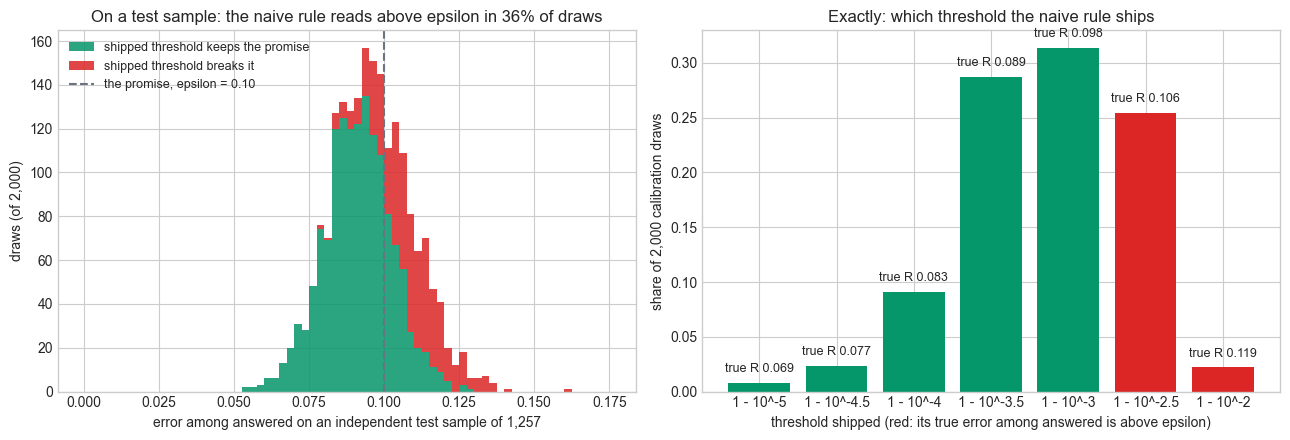

In [6]:
# The exact check: the 2,513 questions as the population, so R(t) is known for every threshold.
m_pop, e_pop = counts_by_threshold(np.arange(n_q))
risk_pop = e_pop / m_pop
# 2,000 calibration sets of 1,256 drawn from it with replacement (i.i.d. by construction), each paired
# with an independent test sample of 1,257 drawn the same way. Shape: draws x (m, e) x thresholds.
boot_rng = np.random.default_rng(RANDOM_SEED + 2)
boot = boot_rng.integers(0, n_q, size=(N_DRAWS, len(cal)))
cnt_boot = np.array([counts_by_threshold(b) for b in boot])
test_rng = np.random.default_rng(RANDOM_SEED + 4)
boot_test = test_rng.integers(0, n_q, size=(N_DRAWS, len(test)))
cnt_boot_test = np.array([counts_by_threshold(b) for b in boot_test])
draw = np.arange(N_DRAWS)


def exactly(choice):
    """True selective risk and population answer rate of each draw's chosen threshold (0 if none)."""
    j = np.maximum(choice, 0)
    return np.where(choice >= 0, risk_pop[j], 0.0), np.where(choice >= 0, m_pop[j] / n_q, 0.0)


def test_reading(choice):
    """Error among answered on each draw's independent test sample, at its chosen threshold (0 if none)."""
    j = np.maximum(choice, 0)
    m, e = cnt_boot_test[draw, 0, j], cnt_boot_test[draw, 1, j]
    return np.where(choice >= 0, e / np.maximum(m, 1), 0.0)


naive_boot = naive_choice(cnt_boot[:, 0], cnt_boot[:, 1], EPSILON)
naive_true_err, naive_true_rate = exactly(naive_boot)
naive_broke = (naive_boot >= 0) & (naive_true_err > EPSILON)
naive_reading = test_reading(naive_boot)
j_nb = np.maximum(naive_boot, 0)
cal_reading = cnt_boot[draw, 1, j_nb] / cnt_boot[draw, 0, j_nb]
print(f"exactly:          the naive rule broke the promise (true R(t) > {EPSILON:.2f}) in {np.mean(naive_broke):.1%} "
      f"of {N_DRAWS:,} calibration draws")
print(f"on a test sample: it read above {EPSILON:.2f} in {np.mean(naive_reading > EPSILON):.1%} of draws")
print("true R(t) near the crossing: " + ", ".join(f"{GRID_LABEL[j]} {risk_pop[j]:.4f}" for j in range(17, 22)))
print("threshold shipped by the naive rule: " + ", ".join(
    f"{GRID_LABEL[j]} {np.mean(naive_boot == j):.1%}" for j in range(len(GRID)) if np.mean(naive_boot == j) >= 0.005))
print(f"calibration reading at the shipped threshold against its true R: draws that broke the promise "
      f"{cal_reading[naive_broke].mean():.4f} against {naive_true_err[naive_broke].mean():.4f}; the others "
      f"{cal_reading[~naive_broke].mean():.4f} against {naive_true_err[~naive_broke].mean():.4f}")
for label in ("1 - 10^-3.5", "1 - 10^-3"):
    j = GRID_LABEL.index(label)
    fixed_reading = cnt_boot_test[:, 1, j] / cnt_boot_test[:, 0, j]
    print(f"a threshold fixed in advance, {label} (true R {risk_pop[j]:.4f}), reads above {EPSILON:.2f} "
          f"on {np.mean(fixed_reading > EPSILON):.1%} of the test samples")

reading_bins = np.arange(0.0, 0.1751, 0.0025)   # wide enough for every reading in sections 3 and 4
assert naive_reading.max() < reading_bins[-1], "a reading would fall off the right edge of the histogram"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist([naive_reading[~naive_broke], naive_reading[naive_broke]], bins=reading_bins,
             stacked=True, color=[GREEN, RED], alpha=0.85,
             label=["shipped threshold keeps the promise", "shipped threshold breaks it"])
axes[0].axvline(EPSILON, color=GRAY, linestyle="--", label=f"the promise, epsilon = {EPSILON:.2f}")
axes[0].set_xlabel(f"error among answered on an independent test sample of {len(test):,}")
axes[0].set_ylabel(f"draws (of {N_DRAWS:,})")
axes[0].set_title(f"On a test sample: the naive rule reads above epsilon in {np.mean(naive_reading > EPSILON):.0%} of draws")
axes[0].legend(fontsize=9)
shown = [j for j in range(len(GRID)) if np.mean(naive_boot == j) >= 0.005]
share = [np.mean(naive_boot == j) for j in shown]
axes[1].bar(range(len(shown)), share, color=[RED if risk_pop[j] > EPSILON else GREEN for j in shown])
for k, j in enumerate(shown):
    axes[1].text(k, share[k] + 0.01, f"true R {risk_pop[j]:.3f}", ha="center", fontsize=9)
axes[1].set_xticks(range(len(shown)))
axes[1].set_xticklabels([GRID_LABEL[j] for j in shown])
axes[1].set_xlabel("threshold shipped (red: its true error among answered is above epsilon)")
axes[1].set_ylabel(f"share of {N_DRAWS:,} calibration draws")
axes[1].set_title("Exactly: which threshold the naive rule ships")
plt.tight_layout()
plt.show()

Exactly, the naive rule broke the promise in 27.7% of the 2,000 calibration draws, nearly three times the one draw in ten the product lead would accept. On an independent test sample it read above 10% in 35.8% of the draws, and the left panel shows why readings cannot settle the question on their own: readings above the line come from thresholds that keep the promise (green) as well as from thresholds that break it (red), and readings below it from both too. Two thresholds fixed in advance make the point without any rule: $1 - 10^{-3}$, truly at 9.78%, reads above 10% on 39.1% of the test samples, and $1 - 10^{-3.5}$, truly at 8.92%, still on 11.3%. On our seeded split the naive rule shipped the first of these. In truth it keeps the promise, and the test half's 10.23% was a reading: on that split the rule was lucky, a luck that fails it in 27.7% of the redraws.

The right panel shows the mechanism. In the population, $1 - 10^{-3}$ is truly fine, and the next half-decade, $1 - 10^{-2.5}$, is truly not (10.63%). The naive rule ships the bad one whenever its calibration error happens to come in at 10% or below, which for a true 10.63% and about 990 answered questions happens in 25.4% of the draws; add the rarer $1 - 10^{-2}$ and the rule ships a bad threshold a little more than one draw in four. Nothing in the rule asks whether 9.9% on a sample is evidence of anything below 10%. Conditioning on the truth makes the point. In the draws where the naive rule broke the promise, the calibration draw had read 9.53% at the threshold it shipped, whose true rate was 10.74%; in the draws where it kept the promise, it had read 9.49% for a true 9.16%. From the calibration draw the two kinds of draw look the same, and the rule cannot tell them apart. That is notebook 19's lesson again: a point estimate is not a bound.

## 4. Certify, then ship

The repair turns every candidate threshold into a hypothesis test and certifies only what the calibration set can defend, in four steps.

1. For each grid threshold $t$, the null hypothesis is "$R(t) > \epsilon$": this threshold breaks the promise. Certifying $t$ means rejecting it.
2. Give each hypothesis a p-value computed on the answered calibration questions only.
3. Test the thresholds in the fixed order of the grid, strictest first, each at the full level delta, and stop at the first one that is not rejected. Every threshold rejected before the stop is certified.
4. Ship the loosest certified threshold. If none is certified, hand every question to a tutor.

**The p-value.** Fix a threshold $t$ before looking at any label. If the calibration questions are independent draws from the traffic the promise is about, then each one, independently, is answered with some probability and, if answered, wrong with probability $R(t)$. Condition on which calibration questions are answered, $m(t)$ of them: those $m(t)$ questions are still independent draws, now from the answered part of the traffic, so the number of them that are wrong, $e(t)$, is $\mathrm{Binomial}\big(m(t), R(t)\big)$. If $R(t) > \epsilon$, a count this low is even less likely than it would be at an error rate of exactly $\epsilon$. So

$$p(t) = \Pr\big(\mathrm{Binomial}(m(t), \epsilon) \le e(t)\big) = \sum_{k=0}^{e(t)} \binom{m(t)}{k} \epsilon^{k} (1 - \epsilon)^{m(t) - k}$$

is a valid p-value given $m(t)$, and therefore also averaged over $m(t)$: under the null, $\Pr\big(p(t) \le \delta\big) \le \delta$. With nothing answered, $p(t) = 1$. Here $m(t)$ is the number of calibration questions answered alone at $t$, $e(t)$ the number of those that are wrong, and $k$ runs over the possible error counts. This is the exact binomial tail bound Learn then Test uses in its selective-classification example (its section 3.2: the risk "conditionally on predicting", computed only on the points that pass the threshold), and the same conditioning argument as the proof of Geifman and El-Yaniv's Theorem 3.2.

**The assumption, exactly.** The calibration questions must be an i.i.d. sample of the questions Quill will serve. That is stronger than anything conformal prediction needed. Split conformal asked only that the calibration questions and the next question be exchangeable: then the next score's rank among the calibration scores is uniform (notebook 03). The binomial count needs independent draws, each wrong with the same probability as a future answered question, and exchangeability does not provide it. Notebook 09's tiles show the gap (its section 2): drawing without replacement from a fixed pool is exchangeable but not independent. Draw the calibration questions that way from a fixed bank and serve the rest of the bank as the future: every error the calibration set catches is one the future does not get, a dependence the binomial ignores. That is why the exact check draws calibration sets with replacement, and why, for Quill, the calibration questions must be a random sample of real traffic drawn independently (field guide §26), answered by the frozen procedure (field guide §25).

**Fixed-sequence testing.** We test 26 hypotheses, and testing each at delta and certifying every one that passes would let the chance of certifying some bad threshold grow with the number of tests. Learn then Test (Angelopoulos, Bates, Candes, Jordan and Lei, arXiv 2110.01052, 2021; the numbers below are those of its fifth version) proves in its Theorem 1 that valid p-values give the promise once they are combined by a procedure that controls the family-wise error rate (notebook 19): the chance of rejecting any true null, at most delta. Fixed-sequence testing (its Algorithm 1 with a single start, and Proposition 3) does so for any order fixed before the calibration data is seen. Why, in words: look at the first threshold in the order that truly breaks the promise. The sequence cannot reach any later threshold without certifying that one first, so it certifies some bad threshold only if that one's p-value is at most delta, which has probability at most delta. Nothing else in the argument matters. The bad thresholds can sit anywhere in the order, interleaved with good ones, which is why $R(t)$ need not be monotone. The guarantee then reads $\Pr\big(R(t) \le \epsilon \text{ for every certified } t\big) \ge 1 - \delta$, so in particular for the one we ship.

Strictest first is the order because the score ranks well (notebook 16): we expect the strict thresholds to pass and the error to grow as we loosen. If a strict threshold unexpectedly fails, the sequence stops there and never tries the looser ones: a loss of answers, never of validity. Two other routes exist. Geifman and El-Yaniv's Selection with Guaranteed Risk (NeurIPS 2017, their Algorithm 1) runs a binary search over thresholds with the same binomial tail bound (their Lemma 3.1, due to Gascuel and Caraux) and splits delta over the $\lceil \log_2 m \rceil$ steps of the search, with $m$ the number of calibration points. Its candidate thresholds are calibration scores picked as the search proceeds, so its per-step bound is applied to thresholds chosen from the same data; a grid fixed before calibrating, as in our simulation, avoids that issue. When the loss can only fall as the parameter grows the sets, risk-controlling prediction sets (Bates, Angelopoulos, Lei, Malik and Jordan, 2021) scan from the safe end with an upper confidence bound; selective risk is a ratio, need not be monotone, and is the kind of risk Learn then Test was built for (field guide §28).

In [7]:
def binomial_pvalues(m, e, eps):
    """LTT p-value for H(t): R(t) > eps: the chance of e or fewer errors among m answered at rate eps.

    Valid given m because the answered calibration questions are i.i.d. draws from the answered
    traffic, so their error count is Binomial(m, R(t)). Nothing answered gives p = 1.
    """
    return np.where(m > 0, stats.binom.cdf(e, m, eps), 1.0)


def certified(m, e, eps, delta):
    """Fixed-sequence testing (LTT Algorithm 1, one start): the grid order, strictest first, each test at
    the full delta, stopping at the first p-value above delta. Returns the mask of certified thresholds."""
    return np.cumprod(binomial_pvalues(m, e, eps) <= delta, axis=-1).astype(bool)


def ltt_choice(m, e, eps, delta):
    """The loosest certified threshold; -1 means nothing is certified: hand every question to a tutor."""
    return loosest(certified(m, e, eps, delta))


pvals = binomial_pvalues(m_cal, e_cal, EPSILON)
cert = certified(m_cal, e_cal, EPSILON, DELTA)
j_ltt = int(ltt_choice(m_cal, e_cal, EPSILON, DELTA))
noise_ltt = 2 * math.sqrt(EPSILON * (1 - EPSILON) / m_test[j_ltt])
print(f"epsilon = {EPSILON}, delta = {DELTA}: {cert.sum()} thresholds certified; the sequence stops at "
      f"{GRID_LABEL[cert.sum()]} (p = {pvals[cert.sum()]:.4f})")
print(f"shipped: {GRID_LABEL[j_ltt]} (t = {GRID[j_ltt]:.6f}), p = {pvals[j_ltt]:.4f}")
print(f"   calibration: answered {m_cal[j_ltt]} ({m_cal[j_ltt] / len(cal):.1%}), wrong {e_cal[j_ltt]}, "
      f"error among answered {risk_cal[j_ltt]:.4f}")
print(f"   test:        answered {m_test[j_ltt]} ({m_test[j_ltt] / len(test):.1%}), wrong {e_test[j_ltt]}, "
      f"error among answered {e_test[j_ltt] / m_test[j_ltt]:.4f} (noise band at 10%: +/- {noise_ltt:.4f})")
print(f"   versus the naive rule on test: {m_test[j_naive] - m_test[j_ltt]} more questions handed to a tutor")
falls = [j for j in range(1, len(GRID)) if risk_pop[j] < risk_pop[j - 1]]
print(f"population R(t) falls on {len(falls)} of {len(GRID) - 1} loosening steps, e.g. "
      f"{GRID_LABEL[6]} {risk_pop[6]:.4f} -> {GRID_LABEL[9]} {risk_pop[9]:.4f}")
sequence = pd.DataFrame({"answered": m_cal, "wrong": e_cal, "error among answered": risk_cal,
                         "p-value": pvals, "certified": cert},
                        index=pd.Index(GRID_LABEL, name="threshold (calibration half)"))
sequence.round(4)

epsilon = 0.1, delta = 0.1: 19 thresholds certified; the sequence stops at 1 - 10^-3 (p = 0.2661)
shipped: 1 - 10^-3.5 (t = 0.999684), p = 0.0645
   calibration: answered 943 (75.1%), wrong 80, error among answered 0.0848
   test:        answered 918 (73.0%), wrong 86, error among answered 0.0937 (noise band at 10%: +/- 0.0198)
   versus the naive rule on test: 30 more questions handed to a tutor
population R(t) falls on 4 of 25 loosening steps, e.g. 1 - 10^-9.5 0.0544 -> 1 - 10^-8 0.0503


,answered,wrong,error among answered,p-value,certified
threshold (calibration half),,,,,
t = 1,92,3,0.0326,0.0145,True
1 - 10^-12,151,5,0.0331,0.0018,True
1 - 10^-11.5,190,9,0.0474,0.0065,True
1 - 10^-11,248,11,0.0444,0.0010,True
1 - 10^-10.5,312,12,0.0385,0.0000,True
1 - 10^-10,361,13,0.0360,0.0000,True
1 - 10^-9.5,428,22,0.0514,0.0002,True
1 - 10^-9,524,28,0.0534,0.0001,True
1 - 10^-8.5,625,33,0.0528,0.0000,True


Read the table from the top, as the sequence does. At $t = 1$, 3 of the 92 answered calibration questions are wrong, and 3 or fewer errors would be very unlikely (p = 0.0145) if the true error rate were 10%: certified. The thresholds that follow, down to $1 - 10^{-4.5}$, pass with p-values of 0.0065 or less, because 151 to 901 answered questions with error rates of 3.3% to 7.2% are strong evidence against 10%. The p-values climb as the error among answered approaches 10%: 0.0212 at $1 - 10^{-4}$, 0.0645 at $1 - 10^{-3.5}$, and 0.2661 at $1 - 10^{-3}$, where the sequence stops. Nineteen thresholds are certified, and we ship the loosest: $t = 1 - 10^{-3.5} = 0.999684$. Quill answers alone when it leaves at most 0.032% of its probability for the other three options.

Notice the threshold where the sequence stopped. At $1 - 10^{-3}$ the calibration error is 9.34%, below 10%, and the naive rule shipped it. The test refuses it: with 964 answered questions, a threshold whose true error rate were exactly 10% would show 90 or fewer errors more than a quarter of the time (p = 0.2661). Below epsilon is not evidence of below epsilon.

On the test half the certified threshold answers 918 of 1,257 questions (73.0%), 86 of them wrong: a reading of 9.37%, under the promised 10%, with the test half's noise of plus or minus 0.0198 around it. In the 2,513-question population its true rate is 8.92%. Against the naive rule, the certificate hands 30 more test questions to a tutor. The last printout is the population's own curve: its error among answered falls on 4 of the 25 loosening steps, for example over the three steps from 5.44% at $1 - 10^{-9.5}$ to 5.03% at $1 - 10^{-8}$. Fixed-sequence testing never needed the curve to be monotone. Remember the note at the end of section 1: this single split is a worked example, one ticket, and the repeated draws are the evidence.

In [8]:
ltt_boot = ltt_choice(cnt_boot[:, 0], cnt_boot[:, 1], EPSILON, DELTA)
ltt_true_err, ltt_true_rate = exactly(ltt_boot)
ltt_broke = (ltt_boot >= 0) & (ltt_true_err > EPSILON)
ltt_reading = test_reading(ltt_boot)

# The shortlist's singletons in the same draws: q_hat from each calibration draw, the true error among
# singletons on the whole population, and the reading on the draw's test sample.
lac_draws = []
for b, b_test in zip(boot, boot_test):
    _, _, single_pop = lac_singletons(b, np.arange(n_q))
    _, _, single_test = lac_singletons(b, b_test)
    lac_draws.append((wrong[single_pop].mean(), single_pop.mean(), wrong[b_test][single_test].mean()))
lac_draws = np.array(lac_draws)

# The same procedure on the 2,000 half-splits of section 2, for comparison: half of one fixed bank varies
# less than an i.i.d. draw of the same size.
cnt_half = np.array([counts_by_threshold(s[: n_q // 2]) for s in splits])
ltt_half = ltt_choice(cnt_half[:, 0], cnt_half[:, 1], EPSILON, DELTA)
half_rate = exactly(ltt_half)[1]

summary = pd.DataFrame({
    "broke the promise (true R > epsilon)": [np.mean(lac_draws[:, 0] > EPSILON), np.mean(naive_broke), np.mean(ltt_broke)],
    "read above epsilon on a test sample": [np.mean(lac_draws[:, 2] > EPSILON), np.mean(naive_reading > EPSILON),
                                            np.mean((ltt_boot >= 0) & (ltt_reading > EPSILON))],
    "mean answer rate": [lac_draws[:, 1].mean(), naive_true_rate.mean(), ltt_true_rate.mean()],
    "nothing answered": [np.mean(lac_draws[:, 1] == 0), np.mean(naive_boot < 0), np.mean(ltt_boot < 0)],
}, index=pd.Index(["singletons of the 90% shortlist", "naive: loosest with calibration error <= epsilon",
                   "certified: fixed-sequence LTT"], name=f"rule (epsilon = {EPSILON}, delta = {DELTA}, {N_DRAWS:,} draws)"))
print(f"mean answer rate: singletons {lac_draws[:, 1].mean():.1%}, naive {naive_true_rate.mean():.1%}, "
      f"certified {ltt_true_rate.mean():.1%} = nothing certified in {np.mean(ltt_boot < 0):.2%} of draws and "
      f"{ltt_true_rate[ltt_boot >= 0].mean():.1%} answered in the others")
print(f"on the 2,000 half-splits instead: nothing certified in {np.mean(ltt_half < 0):.2%}, "
      f"{half_rate[ltt_half >= 0].mean():.1%} answered given a certificate; answered at t = 1: standard deviation "
      f"{cnt_half[:, 0, 0].std():.2f} across half-splits, {cnt_boot[:, 0, 0].std():.2f} across i.i.d. draws")
print(f"the worked split's certified threshold, {GRID_LABEL[j_ltt]}, answers {m_pop[j_ltt] / n_q:.1%} of the bank")
summary.round(4)

mean answer rate: singletons 75.6%, naive 75.7%, certified 63.4% = nothing certified in 6.75% of draws and 68.0% answered in the others
on the 2,000 half-splits instead: nothing certified in 0.70%, 71.8% answered given a certificate; answered at t = 1: standard deviation 6.25 across half-splits, 8.81 across i.i.d. draws
the worked split's certified threshold, 1 - 10^-3.5, answers 74.1% of the bank


,broke the promise (true R > epsilon),read above epsilon on a test sample,mean answer rate,nothing answered
"rule (epsilon = 0.1, delta = 0.1, 2,000 draws)",,,,
singletons of the 90% shortlist,0.2220,0.3095,0.7561,0.0000
naive: loosest with calibration error <= epsilon,0.2765,0.3580,0.7575,0.0000
certified: fixed-sequence LTT,0.0235,0.1075,0.6344,0.0675


The certificate keeps its promise: the threshold it shipped broke it in 2.35% of the draws (47 of 2,000), under delta = 0.10, against 27.7% for the naive rule and 22.2% for the shortlist's singletons. The reading column is what a product review with a fresh test sample would see, and it is not bounded by delta. The certified rule read above 10% on 10.75% of the test samples, a little more than delta, while truly breaking the promise in 2.35% of draws. That is not a contradiction. A certified threshold typically sits a point or two below epsilon, and section 3 showed that a threshold truly at 8.92% reads above 10% on 11.3% of test samples of this size. A test reading above epsilon is a reason to look, not proof that the certificate failed; only the true rate is bounded by delta.

The price is the answer rate. The certified rule answers 63.4% of questions on average, against 75.7% for the naive rule and 75.6% for the shortlist's singletons. The 63.4% has two parts: in 6.75% of the draws nothing was certified and Quill handed everything off, and in the others it answered 68.0% on average. Both parts are worse than for our worked split, whose certified threshold answers 74.1% of the bank. Part of that is the luck of one ticket; part is that independent draws of 1,256 questions vary more than the half-splits of one bank used in section 2 and in the worked example, so the sequence stops early more often. The second printout measures it: on the 2,000 half-splits the same procedure certifies nothing in 0.70% of them and answers 71.8% given a certificate, and the number of calibration questions answered at $t = 1$ has a standard deviation of 6.25 across half-splits against 8.81 across i.i.d. draws. Section 5 is about the draws where the sequence stops at once. One promise is not enough to judge a procedure, so the next figure redoes the exact check for many values of epsilon, each a separate promise declared in advance.

worst epsilon on the sweep: naive broken in 65.2% of draws (epsilon 0.0425); certified rule broken in 8.2% (epsilon 0.1800)
test readings of the certified rule, where something was certified: 0.000 to 0.126


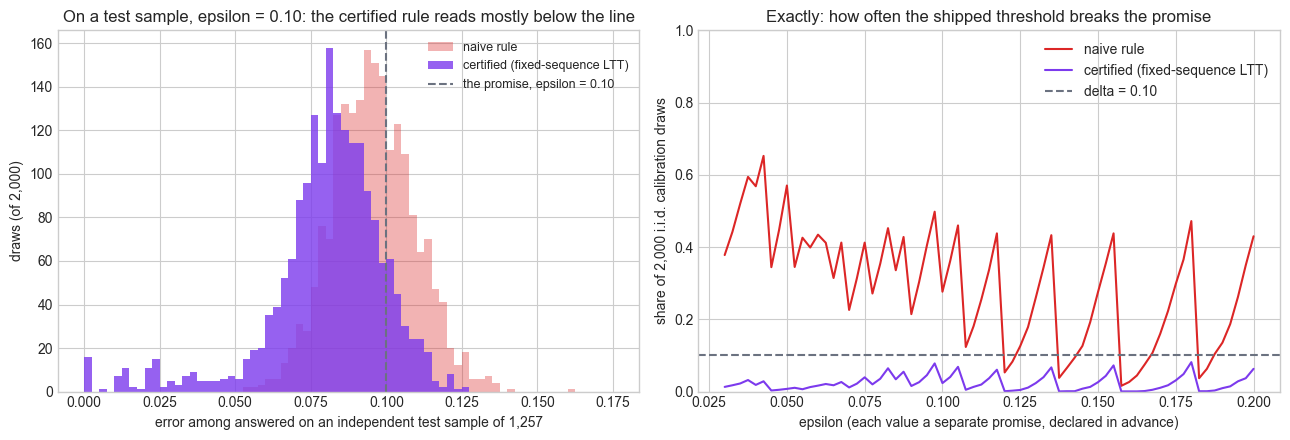

In [9]:
eps_sweep = np.round(np.arange(0.03, 0.2001, 0.0025), 4)
sweep = []
for eps in eps_sweep:
    nv = naive_choice(cnt_boot[:, 0], cnt_boot[:, 1], eps)
    lt = ltt_choice(cnt_boot[:, 0], cnt_boot[:, 1], eps, DELTA)
    (nv_err, nv_rate), (lt_err, lt_rate) = exactly(nv), exactly(lt)
    sweep.append((np.mean((nv >= 0) & (nv_err > eps)), np.mean((lt >= 0) & (lt_err > eps)),
                  nv_rate.mean(), lt_rate.mean()))
sweep = pd.DataFrame(sweep, index=eps_sweep, columns=["naive broken", "LTT broken", "naive answer rate", "LTT answer rate"])
print(f"worst epsilon on the sweep: naive broken in {sweep['naive broken'].max():.1%} of draws "
      f"(epsilon {sweep['naive broken'].idxmax():.4f}); certified rule broken in {sweep['LTT broken'].max():.1%} "
      f"(epsilon {sweep['LTT broken'].idxmax():.4f})")
certified_readings = ltt_reading[ltt_boot >= 0]
assert certified_readings.max() < reading_bins[-1], "a reading would fall off the right edge of the histogram"
print(f"test readings of the certified rule, where something was certified: {certified_readings.min():.3f} to "
      f"{certified_readings.max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(naive_reading, bins=reading_bins, color=RED, alpha=0.35, label="naive rule")
axes[0].hist(ltt_reading[ltt_boot >= 0], bins=reading_bins, color=PURPLE, alpha=0.8, label="certified (fixed-sequence LTT)")
axes[0].axvline(EPSILON, color=GRAY, linestyle="--", label=f"the promise, epsilon = {EPSILON:.2f}")
axes[0].set_xlabel(f"error among answered on an independent test sample of {len(test):,}")
axes[0].set_ylabel(f"draws (of {N_DRAWS:,})")
axes[0].set_title(f"On a test sample, epsilon = {EPSILON:.2f}: the certified rule reads mostly below the line")
axes[0].legend(fontsize=9)
axes[1].plot(sweep.index, sweep["naive broken"], color=RED, label="naive rule")
axes[1].plot(sweep.index, sweep["LTT broken"], color=PURPLE, label="certified (fixed-sequence LTT)")
axes[1].axhline(DELTA, color=GRAY, linestyle="--", label=f"delta = {DELTA:.2f}")
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("epsilon (each value a separate promise, declared in advance)")
axes[1].set_ylabel(f"share of {N_DRAWS:,} i.i.d. calibration draws")
axes[1].set_title("Exactly: how often the shipped threshold breaks the promise")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

The left panel is the table's reading column drawn out: the naive rule's readings straddle the line, the certified rule's sit mostly to its left, and some of them cross it although, as the table showed, the promise itself broke in only 2.35% of draws (draws where nothing was certified are left out; the certified readings run from 0 to 0.126, the lowest from strict thresholds that answer few test questions). The right panel is the theorem at work. For every epsilon from 3% to 20%, the certified rule breaks its promise in at most 8.2% of the draws, under delta, while the naive rule reaches 65.2% at its worst. The red curve is jagged for the reason the bar chart in section 3 showed: it spikes whenever epsilon sits just below a threshold's true error rate, because the naive rule then ships that threshold about as often as a coin lands heads. The purple curve rises towards delta at the same places, and stays under it. The reason is the argument above: the family-wise error of fixed-sequence testing is the chance that the sequence reaches the first bad threshold and certifies it, which is at most the chance that this threshold's p-value is at most delta (compare Learn then Test's Proposition 4). That chance approaches delta only when the first bad threshold's true error rate sits just above epsilon.

Four rules for Quill's answers, side by side:

| Rule | What is promised | Over what randomness | What it assumes | Broke the 10% promise (exactly) / read above 10% on a test sample |
|---|---|---|---|---|
| 90% LAC shortlist (notebook 17) | the shortlist contains the answer key for at least 90% of questions | the calibration draw and the new question, together | calibration and new questions exchangeable | not its promise; 0.889 coverage on this split |
| Answer the shortlist's singletons alone | nothing about the answers given alone beyond error at most alpha / P(answered), on average | the same | the same | 22.2% / 30.95% |
| Naive: loosest threshold with calibration error at most epsilon | nothing | - | - | 27.7% / 35.8% |
| Certified: fixed-sequence Learn then Test | with probability at least 0.90 over the calibration draw, at most 10% of the answers given alone are wrong | the calibration draw only; the promise is about the traffic's error rate | calibration questions an i.i.d. sample of the traffic; epsilon, delta, grid and order fixed before calibrating | 2.35% / 10.75% |

## 5. When nothing is certified

The sequence can stop at its very first threshold. Then nothing is certified, and the honest outcome is that Quill answers nothing alone: every question goes to a tutor. This is not a failure of the method. It is the method reporting that this calibration set cannot support this promise, which is information the product lead needs before launch, not after. It happens for two reasons, usually together: epsilon is too small for the model, or too few calibration questions are answered at the strict thresholds to show it.

Start with the head of learning's wish, one wrong answer in twenty. Suppose the product lead had declared epsilon = 0.05 instead, before calibrating: a separate promise, tested from scratch on the same calibration half. (Declaring 0.05, watching it fail and falling back to 0.10 on the same calibration set would be choosing epsilon after seeing the data, which the theorem does not cover.)

In [10]:
EPS_STRICT = 0.05
p_strict = binomial_pvalues(m_cal, e_cal, EPS_STRICT)
j_strict = int(ltt_choice(m_cal, e_cal, EPS_STRICT, DELTA))
j_naive_strict = int(naive_choice(m_cal, e_cal, EPS_STRICT))
# the largest error count among the 92 answered at t = 1 that could still pass at 0.05
most_errors = int(np.max(np.flatnonzero(stats.binom.cdf(np.arange(m_cal[0] + 1), m_cal[0], EPS_STRICT) <= DELTA),
                         initial=-1))
print(f"epsilon = {EPS_STRICT}: first test, {GRID_LABEL[0]}: {e_cal[0]} wrong of {m_cal[0]} answered, "
      f"p = {p_strict[0]:.4f} > delta = {DELTA}: the sequence stops at once")
print(f"   at t = 1, at most {most_errors} error(s) among {m_cal[0]} could have passed; "
      f"smallest p-value anywhere on the grid: {p_strict.min():.4f} ({GRID_LABEL[int(p_strict.argmin())]})")
print(f"   certified threshold: {'none: hand every question to a tutor' if j_strict < 0 else GRID_LABEL[j_strict]}; "
      f"Quill answers 0 of {len(test):,} test questions alone")
print(f"the naive rule would ship {GRID_LABEL[j_naive_strict]}: calibration error {risk_cal[j_naive_strict]:.4f}, "
      f"test: answered {m_test[j_naive_strict] / len(test):.1%}, error among answered "
      f"{e_test[j_naive_strict] / m_test[j_naive_strict]:.4f}")
nv_s, lt_s = (naive_choice(cnt_boot[:, 0], cnt_boot[:, 1], EPS_STRICT),
              ltt_choice(cnt_boot[:, 0], cnt_boot[:, 1], EPS_STRICT, DELTA))
print(f"   its true rate in the population: {risk_pop[j_naive_strict]:.4f}")
print(f"over {N_DRAWS:,} i.i.d. draws at epsilon = {EPS_STRICT}: nothing certified in {np.mean(lt_s < 0):.1%}; certified rule "
      f"broke the promise in {np.mean((lt_s >= 0) & (exactly(lt_s)[0] > EPS_STRICT)):.2%}, mean answer rate "
      f"{exactly(lt_s)[1].mean():.1%}; naive rule broke it in {np.mean((nv_s >= 0) & (exactly(nv_s)[0] > EPS_STRICT)):.1%}")
print(f"population error among answered at t = 1: {risk_pop[0]:.4f} ({e_pop[0]} of {m_pop[0]})")

epsilon = 0.05: first test, t = 1: 3 wrong of 92 answered, p = 0.3190 > delta = 0.1: the sequence stops at once
   at t = 1, at most 1 error(s) among 92 could have passed; smallest p-value anywhere on the grid: 0.1336 (1 - 10^-10)
   certified threshold: none: hand every question to a tutor; Quill answers 0 of 1,257 test questions alone
the naive rule would ship 1 - 10^-7.5: calibration error 0.0499, test: answered 55.4%, error among answered 0.0532
   its true rate in the population: 0.0515
over 2,000 i.i.d. draws at epsilon = 0.05: nothing certified in 66.2%; certified rule broke the promise in 0.75%, mean answer rate 4.0%; naive rule broke it in 57.0%
population error among answered at t = 1: 0.0242 (4 of 165)


At epsilon = 0.05 the sequence stops at its first step. At $t = 1$, 3 of the 92 answered calibration questions are wrong, and a threshold whose true error rate were exactly 5% would show 3 or fewer errors among 92 about a third of the time (p = 0.3190); at most one error could have passed. No other threshold would have rescued the promise either, in any order: the smallest p-value anywhere on the grid is 0.1336. Nothing is certified, and Quill hands all 1,257 test questions to a tutor.

Compare the naive rule, which never hands anything off. At 0.05 it ships $1 - 10^{-7.5}$, answering 55.4% of the test questions alone with a reading of 5.32%; this time the truth agrees, since that threshold's true rate is 5.15%, and over the redraws the naive rule broke the 5% promise in 57.0% of draws. The certified rule finds nothing to certify in 66.2% of the draws, answers 4.0% of questions on average, and breaks its promise in 0.75% of the draws. The strictest threshold may well meet 5% in truth (the population's error among answered at $t = 1$ is 2.42%, 4 of 165), but 92 calibration questions cannot show it with confidence 0.90. That is the second reason, and it has a formula.

Even with zero errors, a threshold can be certified only if enough calibration questions are answered at it: the p-value of zero errors among $m$ is $(1 - \epsilon)^m$, and it falls to delta only when

$$m \ge \frac{\ln \delta}{\ln(1 - \epsilon)},$$

where $m$ is the number of answered calibration questions, epsilon the promised error rate and delta the tolerance. Below that count no threshold can be certified, however good the model. And because the sequence starts at the strictest threshold, which answers the fewest questions, a small calibration set can end the sequence at step one.

In [11]:
min_answered = {eps: math.ceil(math.log(DELTA) / math.log(1 - eps)) for eps in (0.20, 0.10, 0.05, 0.02, 0.01)}
print("fewest answered calibration questions that can be certified, with zero errors, at delta = 0.10: "
      + ", ".join(f"epsilon {eps}: {k}" for eps, k in min_answered.items()))

# One small calibration set: the first 200 calibration questions in the seeded random order.
small = perm[:200]
m_small, e_small = counts_by_threshold(small)
p_small = binomial_pvalues(m_small, e_small, EPSILON)
print(f"\n200 calibration questions, epsilon = {EPSILON}: first test {GRID_LABEL[0]}: {e_small[0]} wrong of "
      f"{m_small[0]} answered, p = {p_small[0]:.4f}; certified: "
      f"{'none, hand every question to a tutor' if ltt_choice(m_small, e_small, EPSILON, DELTA) < 0 else 'yes'}")
j_ns = int(naive_choice(m_small, e_small, EPSILON))
print(f"   the naive rule would ship {GRID_LABEL[j_ns]}: calibration error {e_small[j_ns] / m_small[j_ns]:.4f} "
      f"on {m_small[j_ns]} answered; test error among answered {e_test[j_ns] / m_test[j_ns]:.4f}")

# The exact check by calibration-set size, at epsilon = 0.10 (1,256 is section 4's set of draws).
size_rng = np.random.default_rng(RANDOM_SEED + 3)
rows = []
for n_cal in (100, 200, 400, 800, len(cal)):
    cnt = cnt_boot if n_cal == len(cal) else np.array(
        [counts_by_threshold(b) for b in size_rng.integers(0, n_q, size=(N_DRAWS, n_cal))])
    lt, nv = ltt_choice(cnt[:, 0], cnt[:, 1], EPSILON, DELTA), naive_choice(cnt[:, 0], cnt[:, 1], EPSILON)
    (lt_err, lt_rate), (nv_err, _) = exactly(lt), exactly(nv)
    rows.append({"calibration questions": n_cal, "mean answered at t = 1": cnt[:, 0, 0].mean(),
                 "certified: nothing certified": np.mean(lt < 0), "certified: broken": np.mean((lt >= 0) & (lt_err > EPSILON)),
                 "certified: mean answer rate": lt_rate.mean(), "naive: broken": np.mean((nv >= 0) & (nv_err > EPSILON))})
pd.DataFrame(rows).set_index("calibration questions").round(4)

fewest answered calibration questions that can be certified, with zero errors, at delta = 0.10: epsilon 0.2: 11, epsilon 0.1: 22, epsilon 0.05: 45, epsilon 0.02: 114, epsilon 0.01: 230

200 calibration questions, epsilon = 0.1: first test t = 1: 1 wrong of 15 answered, p = 0.5490; certified: none, hand every question to a tutor
   the naive rule would ship 1 - 10^-3: calibration error 0.0980 on 153 answered; test error among answered 0.1023


,mean answered at t = 1,certified: nothing certified,certified: broken,certified: mean answer rate,naive: broken
calibration questions,,,,,
100,6.5510,1.0000,0.0000,0.0000,0.4540
200,13.1590,0.9925,0.0000,0.0015,0.4125
400,26.2010,0.5800,0.0145,0.1822,0.3575
800,52.3725,0.2215,0.0255,0.4639,0.2955
1256,82.5730,0.0675,0.0235,0.6344,0.2765


The first line is a planning table to compute before collecting any labels: at delta = 0.10, a threshold needs at least 22 answered calibration questions, all of them right, to be certified at epsilon = 0.10; 45 at 0.05; 114 at 0.02; 230 at 0.01. Real calibration sets contain errors, so the true requirement is larger.

A calibration set of 200 questions shows the trap. At $t = 1$ only 15 of them are answered, 1 is wrong, and the p-value is 0.5490: the sequence stops at its first step and Quill hands everything off, even though looser thresholds answer more questions. The naive rule, unbothered, ships $1 - 10^{-3}$ on the strength of 153 answered questions with a calibration error of 9.80%; on the test half that threshold is wrong 10.23% of the time.

The table repeats the exact check by calibration-set size. With 100 or 200 calibration questions, the strictest threshold answers 6.6 or 13.2 of them on average, below the 22 that a zero-error certificate needs, and nothing is certified in 100.0% and 99.25% of the draws. With 400 questions nothing is certified in 58.0% of draws, with 800 in 22.15%, with 1,256 in 6.75%, and the mean answer rate climbs from 0 to 63.4% as the calibration set grows. The certified rule breaks its promise in at most 2.55% of draws at every size; the naive rule in 28% to 45%, worst when the data is thinnest. More calibration data buys answers, not validity: the certified rule was valid at every size, and the naive rule at none.

Two practical consequences. Size the calibration set from the planning table and the answer rate you hope for: if the threshold you expect to ship answers three questions in four and the strictest one answers one in fourteen, the strictest one decides whether the sequence starts at all. And if you expect small calibration sets, start the sequence at a threshold that answers enough questions, chosen before calibrating, for instance on a pilot set as notebook 19 did. Reordering after seeing which thresholds passed is choosing the test after seeing the data.

## 6. Common mistakes to avoid

1. **Reading a 90% shortlist as "90% of the answers given alone are right".** The singletons of notebook 17's shortlist were wrong 10.3% of the time on this split, and the most the coverage promise could say was 13.1%, on average over calibration draws. Use field guide §7's singleton rule as triage; certify the error among answered separately (field guide §3 and §7).
2. **Shipping the loosest threshold whose calibration error is at most epsilon.** It broke the 10% promise in 27.7% of the i.i.d. calibration draws, because 9.3% on a sample is not evidence of below 10%: when it broke the promise its calibration reading averaged 9.53% for a true 10.74%, indistinguishable from the 9.49% it read when the truth was 9.16% (field guide §28).
3. **Choosing epsilon, delta, the grid or the test order after seeing the calibration data.** Each must be fixed in advance; in particular, falling back from epsilon = 0.05 to 0.10 after 0.05 certified nothing is tuning on the calibration set (notebook 02, field guide §2).
4. **Skipping a failed threshold and testing the next.** Fixed-sequence testing controls the family-wise error only because it stops at the first non-rejection. At epsilon = 0.10 the sequence stopped at $1 - 10^{-3}$ with p = 0.2661; continuing past it would be the naive rule with extra steps.
5. **Treating "nothing certified" as a bug to be fixed by a looser rule.** At epsilon = 0.05, or with 200 calibration questions, the honest answer was to hand every question to a tutor. Plan the calibration size with $\ln \delta / \ln(1 - \epsilon)$ and the expected answer rate at the strictest threshold before you collect labels (field guide §4).
6. **Judging a certificate by one test reading.** The certified rule read above 10% on 10.75% of independent test samples while truly breaking the promise in 2.35% of draws, and a threshold truly at 8.92% reads above 10% on 11.3% of them. A reading above epsilon is a reason to look again, a reading below it is not a proof, and only the true rate is bounded by delta.
7. **Quoting the certificate for traffic it was not calibrated on.** The binomial p-value needs the calibration questions to be an i.i.d. sample of the questions Quill will serve, answered by the same frozen procedure; a public benchmark sampled 90 questions per subject is not Quill's traffic (field guide §25 and §26).

## 7. What to say in the product review

**Strong version**

> "Quill will answer alone only when its top option's probability clears a certified threshold,
> and hand every other question to a tutor. The procedure: 26 candidate thresholds, tested in
> order from the strictest, each with an exact binomial test on the calibration questions it
> would answer, stopping at the first that fails; we ship the loosest that passed. With
> probability at least 90% over the draw of the calibration questions, at most 10% of the answers
> Quill gives alone, on questions like those, are wrong. On 1,256 benchmark questions it certified
> a threshold of 0.999684, which answered 73.0% of 1,257 held-out questions alone, 9.37% of them
> wrong. That run is a worked example, since we had studied these questions before fixing the
> grid. The evidence is a simulation that treats the 2,513 benchmark questions as the population
> and redraws the calibration set 2,000 times: the procedure broke the 10% promise in 2.35% of
> draws, against 27.7% for shipping the loosest threshold whose calibration error was at most 10%,
> and it handed everything to tutors in 6.75% of draws. One wrong answer in twenty cannot be
> certified with this data: at 5% nothing passed. The certificate assumes the calibration
> questions are a random sample of the questions students will ask. Before launch we fix epsilon,
> delta and the grid, then calibrate on a fresh random sample of labelled Quill traffic, with the
> model version and prompt frozen."

**Weak version**

> "Our 90% conformal shortlist guarantees that when Quill shows a single answer it is right at
> least 90% of the time, and on the calibration data the error among answered is 9.3% at a
> threshold of 0.999, so we can let Quill answer about three questions in four on its own."

The weak version gets every load-bearing step wrong. The shortlist's promise is about sets containing the answer key, and for the singletons it implies only 13.1%, on average; on this split they were wrong 10.3% of the time. The 9.3% is the naive rule's calibration reading. The threshold it picked here is truly at 9.78%, so on this split it happened to keep the promise, but the rule that picked it broke the promise in more than a quarter of the redraws (27.7%). It drops delta, the assumption and the benchmark caveat. The strong version states the decision rule, the test, the probability attached to the promise, what the single run can and cannot show, the measured cost in questions handed off, the promise the data refused, and the population the certificate is about.

### The one-line summary

The product lead wanted one answer or none, with at most one wrong answer in ten among the answers Quill gives alone. Notebook 17's 90% shortlist could not promise that: its singletons were wrong 10.3% of the time on test, because a coverage promise bounds the error among answered only by alpha divided by the share answered. Reading the calibration curve and shipping the loosest threshold whose calibration error was at most 10% broke the promise in 27.7% of exact redraws. Turning each threshold into a binomial test on its answered calibration questions, tested strictest first and stopping at the first failure, certified $t = 0.999684$: 73.0% of test questions answered alone, 9.37% of them wrong, and a broken promise in 2.35% of exact redraws, under the 10% allowed. When the promise was one in twenty, or the calibration set held 200 questions, nothing passed, and the honest product handed every question to a tutor.

An answer given alone is a promise, so Quill should give one only where the calibration set can defend it, and hand the rest to someone who can.